In [1]:
!curl -L https://files.wundernn.io/wnn_connectome_starterpack.tar.gz | tar -xz --wildcards '*/baseline/*' '*/utils.py' '*/requirements.txt' '*/METRIC.md' '*/datasets/valid*.parquet'

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.provenance'
tar: Ignoring unknown extended header keyword 'LIBARCHIVE.xattr.com.apple.pr

In [2]:
!ls -lh wnn_connectome_starterpack/baseline wnn_connectome_starterpack/datasets
!ls wnn_connectome_starterpack

wnn_connectome_starterpack/baseline:
total 1.5M
-rw-r--r-- 1  501 staff 753K Dec 31  2019 baseline.onnx
-rw-r--r-- 1  501 staff 701K Dec 31  2019 baseline_submission.zip
drwxr-xr-x 2 root root  4.0K Oct 31 10:14 __pycache__
-rw-r--r-- 1  501 staff  659 Dec 31  2019 README.md
-rw-r--r-- 1  501 staff 3.0K Dec 31  2019 solution.py

wnn_connectome_starterpack/datasets:
total 5.4G
-rw-r--r-- 1 501 staff  88M Dec 31  2019 valid_mask.parquet
-rw-r--r-- 1 501 staff 5.3G Dec 31  2019 valid.parquet
baseline  datasets  METRIC.md  __pycache__  requirements.txt  utils.py


In [3]:
import os
print("CWD:", os.getcwd())
print("\nContents of CWD:")
for f in os.listdir("."):
    print(" ", f)

# If a 'baseline' dir exists, list it:
if os.path.isdir("baseline"):
    print("\nbaseline/:")
    for f in os.listdir("baseline"):
        print(" ", f)

CWD: /content

Contents of CWD:
  .config
  wnn_connectome_starterpack
  sample_data


In [4]:
!pip install onnx
import onnx
m = onnx.load('wnn_connectome_starterpack/baseline/baseline.onnx')
for n in m.graph.node:
    print(n.op_type, n.name)
for i in m.graph.initializer:
    print(i.name, list(i.dims))

Transpose /blocks.0/gru/Transpose
GRU /blocks.0/gru/GRU
Constant /blocks.0/gru/Constant
Squeeze /blocks.0/gru/Squeeze
GRU /blocks.1/gru/GRU
Constant /blocks.1/gru/Constant
Squeeze /blocks.1/gru/Squeeze
Transpose /blocks.1/gru/Transpose
MatMul /reg_head/MatMul
Add /reg_head/Add
reg_head.bias [2]
onnx::GRU_163 [1, 384, 112]
onnx::GRU_164 [1, 384, 128]
onnx::GRU_165 [1, 768]
onnx::GRU_183 [1, 384, 128]
onnx::GRU_184 [1, 384, 128]
onnx::GRU_185 [1, 768]
onnx::MatMul_186 [128, 2]


In [5]:
import pyarrow.parquet as pq, pandas as pd
pf = pq.ParquetFile('wnn_connectome_starterpack/datasets/valid.parquet')
df = pf.read_row_group(0).to_pandas()
X = df.iloc[:, 4:116]
print(X.describe().T[['mean','std','min','max']].to_string())
print(df[['t0','t1']].describe())

            mean       std       min       max
i0_p0  -1.453490  0.426344 -2.336949 -0.549869
i0_p1   0.131099  0.079324 -0.306871  0.235797
i0_p2   0.374947  0.081542 -0.386207  0.724265
i0_p3  -1.482257  0.344322 -2.332640 -0.763644
i0_p4  -0.029738  0.098720 -0.508185  0.406445
i0_p5   0.858976  0.121403  0.640398  1.775279
i0_p6  -0.396921  0.200438 -2.152128 -0.184412
i0_p7  -0.128831  0.064794 -0.672954  0.014948
i0_p8  -0.780703  0.260081 -2.322753 -0.234239
i0_p9  -0.587679  0.369903 -2.328715 -0.189113
i0_p10  1.138526  0.223384  0.761130  2.323518
i0_p11 -1.000955  0.438580 -2.327353 -0.203817
i0_p12  0.277227  0.074391 -0.293575  0.477737
i0_p13  0.636658  0.126863  0.417942  1.812474
i0_p14 -1.382888  0.427000 -2.332138 -0.316087
i0_p15 -0.628866  0.226641 -2.138202 -0.339001
i0_p16  1.615971  0.327436  0.761225  2.333441
i0_p17  0.082630  0.064551 -0.680451  0.336452
i0_p18  0.610472  0.094134  0.222651  1.409339
i0_p19  2.103341  0.239970  1.612318  2.343054
i0_p20  1.197

In [6]:
cols = ['i1_dv0','i1_dv3','a5','a6','a7']
print((X[cols] < -5.19).mean())

i1_dv0    0.00005
i1_dv3    0.00005
a5        0.06275
a6        0.37730
a7        0.44465
dtype: float64


In [7]:
import os
print("CWD:", os.getcwd())
print(os.listdir("."))
if os.path.isdir("baseline"):
    print("baseline/:", os.listdir("baseline"))

CWD: /content
['.config', 'wnn_connectome_starterpack', 'sample_data']


In [8]:
import time, sys, numpy as np, pyarrow.parquet as pq
from types import SimpleNamespace
sys.path.insert(0, '/content/wnn_connectome_starterpack/baseline')
from solution import PredictionModel

pf = pq.ParquetFile('wnn_connectome_starterpack/datasets/valid.parquet')
df = pf.read_row_group(0).to_pandas()
X = df.iloc[:, 4:116].to_numpy(np.float32)
m = PredictionModel()
n = 5000
t = time.time()
for i in range(n):
    m.predict(SimpleNamespace(seq_ix=0, step_in_seq=i, need_prediction=i >= 99, state=X[i]))
dt = (time.time() - t) / n
print(f"{dt*1e6:.0f} мкс/строка -> {dt*39.4e6/60:.0f} мин на тесте")

100 мкс/строка -> 65 мин на тесте


In [9]:
df

,seq_ix,step_in_seq,need_prediction,is_scored,i0_p0,i0_p1,i0_p2,i0_p3,i0_p4,i0_p5,...,a0,a1,a2,a3,a4,a5,a6,a7,t0,t1
0,256678,0,False,False,-1.825227,0.041018,0.294015,-1.755947,0.035652,0.893804,...,-1.311077,-0.537082,-0.917651,-0.700967,-0.663396,-0.584135,-0.354392,0.698526,1.128898,-1.881497
1,256678,1,False,False,-1.825227,0.041018,0.294015,-1.755947,0.035652,0.893804,...,-1.389268,-0.184068,-0.941336,-0.709497,-0.687399,-0.584084,-0.354276,0.908458,1.128898,-1.881497
2,256678,2,False,False,-1.825227,0.041018,0.294015,-1.755947,0.035652,0.893804,...,-1.275817,0.209445,-0.965435,-0.717904,-0.608951,-0.584011,-0.354112,1.073987,1.128898,-1.881497
3,256678,3,False,False,-1.825227,0.041018,0.294015,-1.755947,0.035652,0.893804,...,-1.379323,-0.226197,-0.988646,-0.726195,-0.644772,-0.583958,-0.353994,1.220640,1.128898,-1.881497
4,256678,4,False,False,-1.825227,0.041018,0.294015,-1.755947,0.035652,0.893804,...,-0.952165,0.461430,-1.013666,-0.734457,-0.489785,-0.583826,-0.353699,1.366707,1.128898,-1.881497
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,256678,19995,True,False,-0.808782,0.182612,0.420078,-0.922493,-0.161536,1.109753,...,-0.123412,0.083174,-1.575070,-0.750596,1.072958,-0.728977,-5.199337,-5.199337,0.376299,-0.627166
19996,256678,19996,True,True,-0.987837,0.216904,0.444660,-1.120205,-0.088734,0.764710,...,-0.199705,-0.370758,-1.571504,-0.758429,0.592105,-5.199337,-0.420762,-5.199337,0.376299,-0.627166
19997,256678,19997,True,False,-1.969121,0.053261,0.314378,-1.892478,0.174765,0.730538,...,-0.146819,0.250563,-1.536773,-0.766015,0.863387,-5.199337,-5.199337,-5.199337,-0.250866,-0.376299
19998,256678,19998,True,True,-1.825227,0.041018,0.294015,-1.755947,0.035652,0.893804,...,-0.119126,0.155683,-1.485830,-0.773415,0.975716,-0.787650,-0.402119,-5.199337,-0.250866,-0.376299


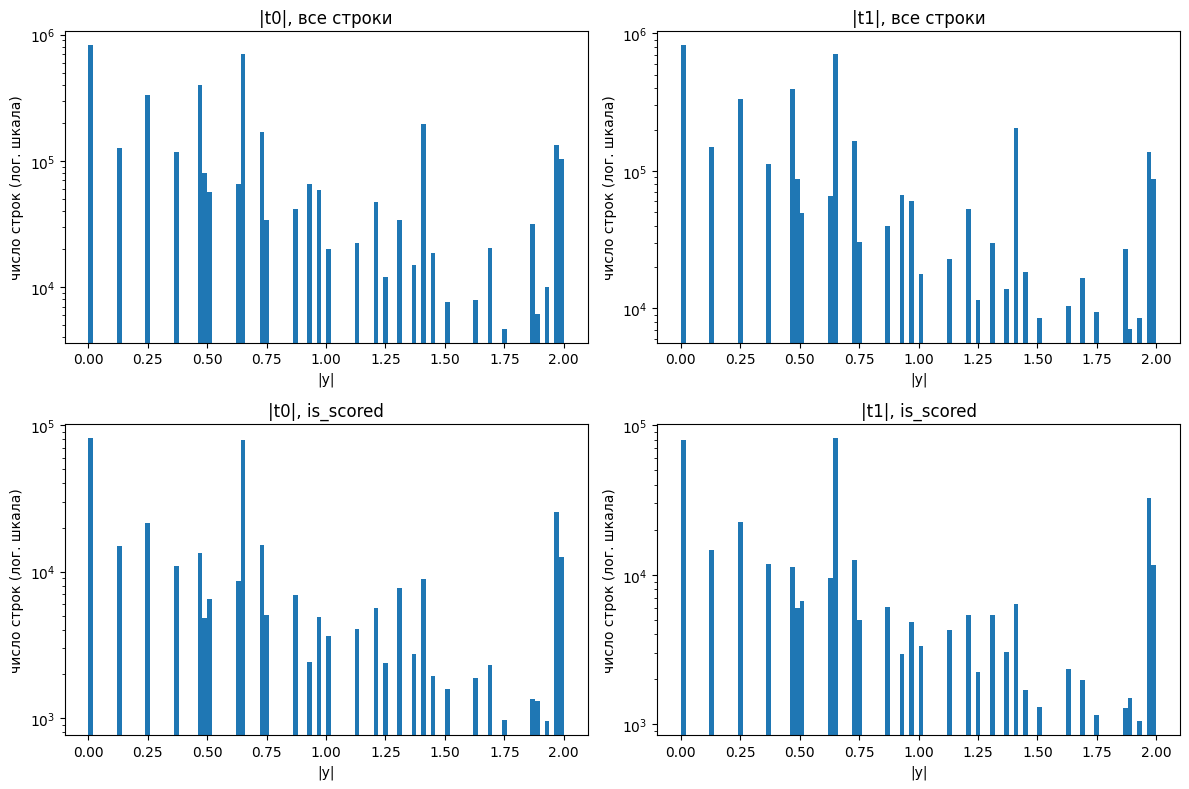

t0 доля нулей (все): 0.218 | доля нулей (is_scored): 0.226 | доля is_scored: 0.096 | уникальных значений: 63
t1 доля нулей (все): 0.217 | доля нулей (is_scored): 0.221 | доля is_scored: 0.096 | уникальных значений: 63


In [17]:
import numpy as np
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

pf = pq.ParquetFile('wnn_connectome_starterpack/datasets/valid.parquet')
idx = range(0, pf.num_row_groups, 10)   # каждая 10-я последовательность, ~190 штук

t0, t1, sc = [], [], []
for i in idx:
    tb = pf.read_row_group(i, columns=['t0', 't1', 'is_scored'])  # только нужные колонки
    t0.append(tb['t0'].to_numpy())
    t1.append(tb['t1'].to_numpy())
    sc.append(tb['is_scored'].to_numpy())
t0, t1, sc = map(np.concatenate, (t0, t1, sc))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, (name, y) in enumerate([('t0', t0), ('t1', t1)]):
    y = np.clip(y, -2, 2)
    # все строки vs строки с is_scored
    for row, (label, m) in enumerate([('все строки', slice(None)), ('is_scored', sc)]):
        ax = axes[row, col]
        ax.hist(np.abs(y[m]), bins=100, log=True)
        ax.set_title(f'|{name}|, {label}')
        ax.set_xlabel('|y|')
        ax.set_ylabel('число строк (лог. шкала)')
plt.tight_layout()
plt.show()

for name, y in [('t0', t0), ('t1', t1)]:
    y = np.clip(y, -2, 2)
    print(name,
          'доля нулей (все):', round((y == 0).mean(), 3),
          '| доля нулей (is_scored):', round((y[sc] == 0).mean(), 3),
          '| доля is_scored:', round(sc.mean(), 3),
          '| уникальных значений:', len(np.unique(y)))

In [18]:
import numpy as np
import pyarrow.parquet as pq

STRIDE = 1   # 1 = все 1873 последовательности, 4 = каждая четвёртая
L = 20000

pf = pq.ParquetFile('wnn_connectome_starterpack/datasets/valid.parquet')
t0, t1, sc = [], [], []
for i in range(0, pf.num_row_groups, STRIDE):
    tb = pf.read_row_group(i, columns=['t0', 't1', 'is_scored'])
    t0.append(tb['t0'].to_numpy()); t1.append(tb['t1'].to_numpy()); sc.append(tb['is_scored'].to_numpy())
t0, t1, sc = np.concatenate(t0), np.concatenate(t1), np.concatenate(sc)
assert len(t0) % L == 0
n_seq = len(t0) // L
y0, y1 = np.clip(t0, -2, 2).astype(np.float64), np.clip(t1, -2, 2).astype(np.float64)
print(f'последовательностей: {n_seq}, строк: {len(t0):,}, is_scored: {sc.mean():.3f}')

def groups(a):
    return [('ноль', a == 0), ('(0, 0.5]', (a > 0) & (a <= 0.5)), ('(0.5, 1]', (a > 0.5) & (a <= 1)),
            ('(1, 1.5]', (a > 1) & (a <= 1.5)), ('(1.5, 2)', (a > 1.5) & (a < 2)), ('=2 (насыщ.)', a >= 2)]

# ---------- 1. Откуда берётся вес метрики ----------
def weight_report(name, y, mask, title):
    ys = y[mask]; a = np.abs(ys)
    m = (a * ys).sum() / a.sum()                 # взвешенное среднее
    contrib = a * (ys - m) ** 2                  # вклад строки во взвешенную дисперсию y
    print(f'\n[1] {name}, {title}: доля строк / доля веса |y| / доля взвеш. дисперсии')
    for lab, g in groups(a):
        print(f'  {lab:12s} {g.mean():7.3f} {a[g].sum() / a.sum():8.3f} {contrib[g].sum() / contrib.sum():8.3f}')

for name, y in [('t0', y0), ('t1', y1)]:
    weight_report(name, y, np.ones_like(sc, bool), 'все строки')
    weight_report(name, y, sc, 'is_scored')

# ---------- 2. Знак и сетка таргета ----------
for name, y in [('t0', y0), ('t1', y1)]:
    nz = y[y != 0]
    print(f'\n[2] {name}: среднее y = {y.mean():.4f}, доля >0 среди ненулевых = {(nz > 0).mean():.3f}')
    v, c = np.unique(np.round(y, 4), return_counts=True)
    d = dict(zip(v, c))
    print('  |y|      count(-)    count(+)')
    for val in sorted(x for x in d if x > 0):
        print(f'  {val:6.4f} {d.get(-val, 0):10d} {d.get(val, 0):10d}')

# ---------- 3. Связь между t0 и t1 ----------
for title, m in [('все строки', np.ones_like(sc, bool)), ('is_scored', sc)]:
    a, b = y0[m], y1[m]
    both = (a != 0) & (b != 0)
    print(f'\n[3] {title}: corr(t0,t1) = {np.corrcoef(a, b)[0, 1]:.3f}, '
          f'доля t0==t1: {(a == b).mean():.3f}, '
          f'совпадение знака среди обоих ненулевых: {(np.sign(a[both]) == np.sign(b[both])).mean():.3f}')

# ---------- 4. Где лежит маска ----------
S = sc.reshape(n_seq, L)
per_seq = S.sum(1)
starts = (np.diff(S.astype(np.int8), axis=1) == 1).sum(1) + S[:, 0]
print(f'\n[4] scored на последовательность: min {per_seq.min()}, медиана {int(np.median(per_seq))}, max {per_seq.max()}, '
      f'без единой: {(per_seq == 0).sum()}')
print(f'    scored в прогреве (шаги 0-98): {S[:, :99].sum()}')
print(f'    блоков подряд на последовательность (медиана): {int(np.median(starts))}, '
      f'медианная длина блока: {np.median(per_seq / np.maximum(starts, 1)):.0f}')
print('    доля scored по тысячам шагов:', np.round(S.reshape(n_seq, 20, 1000).mean(axis=(0, 2)), 3))
a = np.abs(y0)
print('    P(is_scored | |t0|):', {lab: round(float(sc[g].mean()), 3) for lab, g in groups(a)})

последовательностей: 1873, строк: 37,460,000, is_scored: 0.094

[1] t0, все строки: доля строк / доля веса |y| / доля взвеш. дисперсии
  ноль           0.218    0.000    0.000
  (0, 0.5]       0.275    0.153    0.016
  (0.5, 1]       0.328    0.374    0.090
  (1, 1.5]       0.094    0.205    0.215
  (1.5, 2)       0.059    0.184    0.389
  =2 (насыщ.)    0.026    0.084    0.290

[1] t0, is_scored: доля строк / доля веса |y| / доля взвеш. дисперсии
  ноль           0.221    0.000    0.000
  (0, 0.5]       0.189    0.082    0.008
  (0.5, 1]       0.354    0.354    0.078
  (1, 1.5]       0.100    0.184    0.171
  (1.5, 2)       0.103    0.285    0.469
  =2 (насыщ.)    0.033    0.096    0.274

[1] t1, все строки: доля строк / доля веса |y| / доля взвеш. дисперсии
  ноль           0.216    0.000    0.000
  (0, 0.5]       0.279    0.155    0.016
  (0.5, 1]       0.327    0.374    0.092
  (1, 1.5]       0.095    0.209    0.220
  (1.5, 2)       0.057    0.179    0.381
  =2 (насыщ.)    0.025   

In [19]:
import numpy as np
import pyarrow.parquet as pq

STRIDE, L = 1, 20000
pf = pq.ParquetFile('wnn_connectome_starterpack/datasets/valid.parquet')
t0, t1, sc = [], [], []
for i in range(0, pf.num_row_groups, STRIDE):
    tb = pf.read_row_group(i, columns=['t0', 't1', 'is_scored'])
    t0.append(tb['t0'].to_numpy()); t1.append(tb['t1'].to_numpy()); sc.append(tb['is_scored'].to_numpy())
y0 = np.clip(np.concatenate(t0), -2, 2).astype(np.float64)
y1 = np.clip(np.concatenate(t1), -2, 2).astype(np.float64)
sc = np.concatenate(sc)
n_seq = len(y0) // L
allrows = np.ones_like(sc, bool)

def wcorr(y, p):
    """Взвешенная корреляция по формулам с сайта: w = |y|, взвешенные средние."""
    y = np.clip(y, -2, 2); p = np.clip(p, -2, 2); w = np.abs(y); sw = w.sum()
    my, mp = (w * y).sum() / sw, (w * p).sum() / sw
    cov = (w * (y - my) * (p - mp)).sum() / sw
    vy, vp = (w * (y - my) ** 2).sum() / sw, (w * (p - mp) ** 2).sum() / sw
    return 0.0 if vp == 0 else cov / np.sqrt(vy * vp)

# ---------- (а) Что даст «знание только величины движения» (оракул, на тесте его нет) ----------
def e_y_given_abs(y):
    u, inv = np.unique(np.round(np.abs(y), 4), return_inverse=True)
    return (np.bincount(inv, weights=y) / np.bincount(inv))[inv]

predictors = {
    'p = -|y|':          lambda y: -np.abs(y),
    'p = -1[|y|>=1]':    lambda y: -(np.abs(y) >= 1).astype(np.float64),
    'p = E[y | |y|]':    e_y_given_abs,
    'p = y (проверка=1)': lambda y: y,
}
for title, m in [('все строки', allrows), ('is_scored', sc)]:
    print(f'\n[а] {title}')
    for name, fn in predictors.items():
        s0, s1 = wcorr(y0[m], fn(y0[m])), wcorr(y1[m], fn(y1[m]))
        print(f'  {name:20s} t0 {s0:6.3f}  t1 {s1:6.3f}  среднее {(s0 + s1) / 2:6.3f}')

# ---------- (б) Семейства значений сетки по последовательностям ----------
GRID = {
    1: [0.1254, 0.2509, 0.3763, 0.5017, 0.6272, 0.7526, 0.8780, 1.0035, 1.1289, 1.2543, 1.3798, 1.5052, 1.6306, 1.7561, 1.8815],
    2: [0.2413, 0.4827, 0.7240, 0.9653, 1.2066, 1.4480, 1.6893, 1.9306],
    3: [0.4685, 0.9371, 1.4056, 1.8741],
    4: [0.6569, 1.3137, 1.9706],
}
vals = np.array([v for k in GRID for v in GRID[k]]); fams = np.array([k for k in GRID for _ in GRID[k]])
o = np.argsort(vals); vals, fams = vals[o], fams[o]

def family_of(a):
    idx = np.clip(np.searchsorted(vals, a), 1, len(vals) - 1)
    j = np.where(np.abs(a - vals[idx - 1]) <= np.abs(a - vals[idx]), idx - 1, idx)
    f = fams[j].copy()
    f[np.abs(a - vals[j]) > 2e-3] = 0          # 0 = ноль, насыщение 2.0 или вне сетки
    return f

def seq_counts(y):
    a = np.abs(y); f = family_of(a)
    off = ((a > 0) & (a < 2) & (f == 0)).sum()
    print(f'  строк вне сетки (0<|y|<2): {off}')
    F = f.reshape(n_seq, L)
    return np.stack([(F == k).sum(1) for k in range(1, 5)], axis=1)

dom = {}
for name, y in [('t0', y0), ('t1', y1)]:
    print(f'\n[б] {name}')
    C = seq_counts(y)
    tot = np.maximum(C.sum(1), 1)
    share = C.max(1) / tot
    print('  семейств с долей >=2% в последовательности (0..4):', np.bincount((C / tot[:, None] >= 0.02).sum(1), minlength=5))
    print('  доля главного семейства, квантили 0/5/25/50/75/100%:', np.round(np.quantile(share, [0, .05, .25, .5, .75, 1]), 3))
    print('  главное семейство (1..4):', np.bincount(C.argmax(1) + 1, minlength=5)[1:])
    dom[name] = C.argmax(1)
ct = np.bincount(dom['t0'] * 4 + dom['t1'], minlength=16).reshape(4, 4)
print('\n  главное семейство: строки t0 (1..4), столбцы t1 (1..4)\n', ct)

# ---------- (в) Знаки t0 против t1 ----------
sg = lambda a: (np.sign(a).astype(int) + 1)
for title, m in [('все строки', allrows), ('is_scored', sc)]:
    tab = np.bincount(sg(y0[m]) * 3 + sg(y1[m]), minlength=9).reshape(3, 3) / m.sum()
    print(f'\n[в] {title}: доли; строки t0 (-,0,+), столбцы t1 (-,0,+)\n', np.round(tab, 3))


[а] все строки
  p = -|y|             t0 -0.021  t1 -0.024  среднее -0.023
  p = -1[|y|>=1]       t0 -0.002  t1 -0.003  среднее -0.002
  p = E[y | |y|]       t0  0.658  t1  0.661  среднее  0.660
  p = y (проверка=1)   t0  1.000  t1  1.000  среднее  1.000

[а] is_scored
  p = -|y|             t0  0.093  t1  0.106  среднее  0.100
  p = -1[|y|>=1]       t0  0.046  t1  0.051  среднее  0.048
  p = E[y | |y|]       t0  0.665  t1  0.667  среднее  0.666
  p = y (проверка=1)   t0  1.000  t1  1.000  среднее  1.000

[б] t0
  строк вне сетки (0<|y|<2): 0
  семейств с долей >=2% в последовательности (0..4): [   0 1873    0    0    0]
  доля главного семейства, квантили 0/5/25/50/75/100%: [1. 1. 1. 1. 1. 1.]
  главное семейство (1..4): [398 347 431 697]

[б] t1
  строк вне сетки (0<|y|<2): 0
  семейств с долей >=2% в последовательности (0..4): [   0 1873    0    0    0]
  доля главного семейства, квантили 0/5/25/50/75/100%: [1. 1. 1. 1. 1. 1.]
  главное семейство (1..4): [398 347 431 697]

  главно

In [20]:
import numpy as np
import pyarrow.parquet as pq
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

pf = pq.ParquetFile('wnn_connectome_starterpack/datasets/valid.parquet')
meta = {'seq_ix', 'step_in_seq', 'need_prediction', 'is_scored', 't0', 't1'}
feat = [c for c in pf.schema_arrow.names if c not in meta]
assert len(feat) == 112

STRIDE_G = 30
X, T, Y, SEQ = [], [], [], []
for i in range(0, pf.num_row_groups, STRIDE_G):
    tb = pf.read_row_group(i, columns=feat + ['t0', 't1', 'is_scored'])
    f = np.column_stack([tb[c].to_numpy() for c in feat]).astype(np.float32)
    d = np.abs(np.diff(f, axis=0, prepend=f[:1]))
    X.append(np.hstack([f, d])[99:])
    T.append(np.clip(np.column_stack([tb['t0'].to_numpy(), tb['t1'].to_numpy()]), -2, 2)[99:])
    Y.append(tb['is_scored'].to_numpy()[99:])
    SEQ.append(np.full(20000 - 99, i))
X, T, Y, SEQ = np.vstack(X), np.vstack(T), np.concatenate(Y), np.concatenate(SEQ)
STEP = np.tile(np.arange(99, 20000), len(np.unique(SEQ)))[:, None].astype(np.float32)

rng = np.random.default_rng(0)
useq = np.unique(SEQ); rng.shuffle(useq)
te = np.isin(SEQ, useq[: len(useq) * 3 // 10]); tr = ~te
tr_idx = rng.choice(np.where(tr)[0], 400_000, replace=False)
print('строк:', len(Y), '| доля is_scored:', round(Y.mean(), 3))

def run(name, A):
    clf = HistGradientBoostingClassifier(max_iter=150, random_state=0).fit(A[tr_idx], Y[tr_idx])
    print(f'{name:36s} AUC = {roc_auc_score(Y[te], clf.predict_proba(A[te])[:, 1]):.3f}')

run('только номер шага', STEP)
run('признаки (112 + |diff|), причинные', X)
run('|t0|,|t1| (оракул, из будущего)', np.abs(T))
run('признаки + |t0|,|t1|', np.hstack([X, np.abs(T)]))

строк: 1253763 | доля is_scored: 0.1
только номер шага                    AUC = 0.513
признаки (112 + |diff|), причинные   AUC = 0.862
|t0|,|t1| (оракул, из будущего)      AUC = 0.711
признаки + |t0|,|t1|                 AUC = 0.866


In [21]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

clf = HistGradientBoostingClassifier(max_iter=150, random_state=0).fit(X[tr_idx], Y[tr_idx])
Xt, Yt, St = X[te], Y[te], SEQ[te]
p = clf.predict_proba(Xt)[:, 1]
print('AUC общий:', round(roc_auc_score(Yt, p), 3))

# AUC внутри каждой последовательности: убирает эффект «тип последовательности»
aucs = [roc_auc_score(Yt[St == s], p[St == s]) for s in np.unique(St)
        if 0 < Yt[St == s].sum() < (St == s).sum()]
print('AUC внутри последовательностей: медиана', round(np.median(aucs), 3),
      'квартили', np.round(np.quantile(aucs, [.25, .75]), 3))

# Одиночные признаки: какие сами по себе разделяют маску
names = feat + ['d_' + c for c in feat]
sub = rng.choice(len(Yt), 200_000, replace=False)
single = sorted(((max(a, 1 - a), n) for n, a in
                 ((n, roc_auc_score(Yt[sub], Xt[sub, j])) for j, n in enumerate(names))), reverse=True)
print('топ одиночных признаков:', [(round(a, 3), n) for a, n in single[:12]])

# Перестановочная важность по группам колонок
def idx(lo, hi): return list(range(lo, hi)) + list(range(112 + lo, 112 + hi))
groups = {'i0 стакан цены': idx(0, 22), 'i0 стакан объёмы': idx(22, 44), 'i0 сделки': idx(44, 52),
          'i1 стакан цены': idx(52, 74), 'i1 стакан объёмы': idx(74, 96), 'i1 сделки': idx(96, 104),
          'a0..a7': idx(104, 112)}
base = roc_auc_score(Yt, p)
for g, cols in groups.items():
    Xp = Xt.copy()
    Xp[:, cols] = Xp[rng.permutation(len(Xp))][:, cols]
    print(f'  без {g:18s} AUC {roc_auc_score(Yt, clf.predict_proba(Xp)[:, 1]):.3f}  (было {base:.3f})')

AUC общий: 0.862
AUC внутри последовательностей: медиана 0.819 квартили [0.787 0.866]
топ одиночных признаков: [(np.float64(0.626), 'a4'), (np.float64(0.611), 'a3'), (np.float64(0.591), 'i1_v4'), (np.float64(0.583), 'a0'), (np.float64(0.578), 'a5'), (np.float64(0.576), 'a7'), (np.float64(0.565), 'i1_v18'), (np.float64(0.561), 'i0_v13'), (np.float64(0.556), 'i1_p18'), (np.float64(0.556), 'i0_v18'), (np.float64(0.555), 'i1_p6'), (np.float64(0.553), 'i0_v1')]
  без i0 стакан цены     AUC 0.819  (было 0.862)
  без i0 стакан объёмы   AUC 0.827  (было 0.862)
  без i0 сделки          AUC 0.826  (было 0.862)
  без i1 стакан цены     AUC 0.848  (было 0.862)
  без i1 стакан объёмы   AUC 0.846  (было 0.862)
  без i1 сделки          AUC 0.856  (было 0.862)
  без a0..a7             AUC 0.694  (было 0.862)


In [23]:
import numpy as np, warnings, pyarrow.parquet as pq
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix
from sklearn.feature_selection import f_classif
warnings.filterwarnings('ignore')

pf = pq.ParquetFile('wnn_connectome_starterpack/datasets/valid.parquet')
meta = {'seq_ix', 'step_in_seq', 'need_prediction', 'is_scored', 't0', 't1'}
feat = [c for c in pf.schema_arrow.names if c not in meta]
assert len(feat) == 112

GRID = {1: [0.1254 * k for k in range(1, 16)], 2: [0.2413 * k for k in range(1, 9)],
        3: [0.4685 * k for k in range(1, 5)], 4: [0.6569 * k for k in range(1, 4)]}
vals = np.array([v for k in GRID for v in GRID[k]]); fams = np.array([k for k in GRID for _ in GRID[k]])
WINDOWS, STRIDE = [99, 1000, 5000], 1

def seq_family(t):
    a = np.abs(np.clip(t, -2, 2)); a = a[(a > 0) & (a < 2)]
    j = np.abs(a[:, None] - vals[None, :]).argmin(1)
    return np.bincount(fams[j], minlength=5)[1:].argmax()      # 0..3

def window_stats(f):
    d = np.abs(np.diff(f, axis=0)); dn = np.where(d > 0, d, np.nan)
    return np.concatenate([f.mean(0), f.std(0), d.mean(0), (d == 0).mean(0), np.nanmin(dn, axis=0)])

labels, feats = [], {w: [] for w in WINDOWS}
for i in range(0, pf.num_row_groups, STRIDE):
    tb = pf.read_row_group(i, columns=feat + ['t0'])
    labels.append(seq_family(tb['t0'].to_numpy()))
    tb = tb.slice(0, max(WINDOWS))
    f = np.column_stack([tb[c].to_numpy() for c in feat]).astype(np.float64)
    for w in WINDOWS:
        feats[w].append(window_stats(f[:w]))

y = np.array(labels)
print('классы:', np.bincount(y), '| доля самого частого:', round(np.bincount(y).max() / len(y), 3))
names = [f'{s}_{c}' for s in ['mean', 'std', 'absdiff', 'zerofrac', 'min_nz_diff'] for c in feat]

skf = StratifiedKFold(5, shuffle=True, random_state=0)
for w in WINDOWS:
    A = np.array(feats[w])
    pred = cross_val_predict(HistGradientBoostingClassifier(max_iter=100, random_state=0), A, y, cv=skf)
    print(f'\nокно {w}: accuracy {(pred == y).mean():.3f}')
    print(confusion_matrix(y, pred))

A = np.nan_to_num(np.array(feats[max(WINDOWS)]), nan=0.0)
F, _ = f_classif(A, y)
top = np.argsort(-np.nan_to_num(F))[:12]
print('\nтоп признаков по F-статистике (окно 5000):', [(names[j], round(float(F[j]), 1)) for j in top])

классы: [398 347 431 697] | доля самого частого: 0.372

окно 99: accuracy 0.999
[[398   0   0   0]
 [  0 346   0   1]
 [  1   0 430   0]
 [  0   0   0 697]]

окно 1000: accuracy 0.998
[[398   0   0   0]
 [  0 345   0   2]
 [  0   0 430   1]
 [  0   0   0 697]]

окно 5000: accuracy 0.998
[[397   0   0   1]
 [  0 346   0   1]
 [  0   0 431   0]
 [  1   0   0 696]]

топ признаков по F-статистике (окно 5000): [('mean_i0_v0', 5590.1), ('std_i0_p14', 4319.1), ('mean_i0_v17', 3925.1), ('std_i1_p16', 3828.0), ('mean_i0_v9', 3781.2), ('zerofrac_i1_v17', 3429.2), ('zerofrac_i1_v18', 3423.6), ('zerofrac_i1_v16', 3411.9), ('zerofrac_i1_v12', 3411.2), ('zerofrac_i1_v13', 3410.0), ('zerofrac_i1_v14', 3409.4), ('zerofrac_i1_v15', 3409.2)]


In [26]:
import numpy as np
import pyarrow.parquet as pq

L = 20000
pf = pq.ParquetFile('wnn_connectome_starterpack/datasets/valid.parquet')
UNITS = {1: 0.1254, 2: 0.2413, 3: 0.4685, 4: 0.6569}
G = {k: [u * j for j in range(1, int(2 / u) + 1)] for k, u in UNITS.items()}
vals = np.array([v for k in G for v in G[k]]); fams = np.array([k for k in G for _ in G[k]])

t0, t1, sc = [], [], []
fam = []
for i in range(pf.num_row_groups):
    tb = pf.read_row_group(i, columns=['t0', 't1', 'is_scored'])
    a = np.clip(tb['t0'].to_numpy(), -2, 2)
    t0.append(a); t1.append(np.clip(tb['t1'].to_numpy(), -2, 2)); sc.append(tb['is_scored'].to_numpy())
    b = np.abs(a); b = b[(b > 0) & (b < 2)]
    fam.append(np.bincount(fams[np.abs(b[:, None] - vals[None, :]).argmin(1)], minlength=5)[1:].argmax() + 1)
y0, y1, sc = np.concatenate(t0).astype(np.float64), np.concatenate(t1).astype(np.float64), np.concatenate(sc)
F = np.repeat(np.array(fam), L)

def oracle(y):
    u, inv = np.unique(np.round(np.abs(y), 4), return_inverse=True)
    return (np.bincount(inv, weights=y) / np.bincount(inv))[inv]

def shares(y, m):
    """доли по семействам внутри маски m: строки, вес |y|^3, числитель корреляции оракула"""
    ys, fs = y[m], F[m]
    w = np.abs(ys); sw = w.sum()
    p = oracle(y)[m]
    my, mp = (w * ys).sum() / sw, (w * p).sum() / sw
    var_c = w * (ys - my) ** 2
    cov_c = w * (ys - my) * (p - mp)
    out = []
    for f in range(1, 5):
        g = fs == f
        out.append((g.mean(), var_c[g].sum() / var_c.sum(), cov_c[g].sum() / cov_c.sum()))
    return out

allrows = np.ones_like(sc, bool)
for name, y in [('t0', y0), ('t1', y1)]:
    for title, m in [('все строки', allrows), ('is_scored', sc)]:
        print(f'\n{name}, {title}: семейство (единица) | доля строк | доля взвеш. дисперсии | доля числителя корреляции')
        for f, (r, v, c) in zip(range(1, 5), shares(y, m)):
            print(f'  {f} ({UNITS[f]:.4f})  {r:6.3f}  {v:6.3f}  {c:6.3f}')

print('\nдоля is_scored по семействам:', {f: round(float(sc[F == f].mean()), 3) for f in range(1, 5)})

print('\nP(y>0) по k внутри семейства, t0 (count в скобках), только ненулевые:')
for f in range(1, 5):
    ys = y0[F == f]
    k = np.round(np.abs(ys) / UNITS[f]).astype(int)
    row = []
    for kk in range(1, int(2 / UNITS[f]) + 2):
        g = (k == kk) & (ys != 0)
        if g.sum() > 5000:
            row.append(f'k={kk}: {np.mean(ys[g] > 0):.2f} ({g.sum()//1000}к)')
    print(f'  семейство {f}:', ' | '.join(row))


t0, все строки: семейство (единица) | доля строк | доля взвеш. дисперсии | доля числителя корреляции
  1 (0.1254)   0.212   0.227   0.218
  2 (0.2413)   0.185   0.202   0.181
  3 (0.4685)   0.230   0.250   0.194
  4 (0.6569)   0.372   0.320   0.407

t0, is_scored: семейство (единица) | доля строк | доля взвеш. дисперсии | доля числителя корреляции
  1 (0.1254)   0.281   0.306   0.266
  2 (0.2413)   0.152   0.146   0.104
  3 (0.4685)   0.081   0.071   0.049
  4 (0.6569)   0.486   0.476   0.581

t1, все строки: семейство (единица) | доля строк | доля взвеш. дисперсии | доля числителя корреляции
  1 (0.1254)   0.212   0.239   0.241
  2 (0.2413)   0.185   0.195   0.164
  3 (0.4685)   0.230   0.240   0.192
  4 (0.6569)   0.372   0.326   0.403

t1, is_scored: семейство (единица) | доля строк | доля взвеш. дисперсии | доля числителя корреляции
  1 (0.1254)   0.281   0.296   0.252
  2 (0.2413)   0.152   0.155   0.121
  3 (0.4685)   0.081   0.066   0.041
  4 (0.6569)   0.486   0.483   0.587

д

In [27]:
import numpy as np
import pyarrow.parquet as pq

L = 20000
UNITS = {1: 0.1254, 2: 0.2413, 3: 0.4685, 4: 0.6569}

if 'F' not in globals():
    pf = pq.ParquetFile('wnn_connectome_starterpack/datasets/valid.parquet')
    G = {k: [u * j for j in range(1, int(2 / u) + 1)] for k, u in UNITS.items()}
    vals = np.array([v for k in G for v in G[k]]); fams = np.array([k for k in G for _ in G[k]])
    t0, t1, sc, fam = [], [], [], []
    for i in range(pf.num_row_groups):
        tb = pf.read_row_group(i, columns=['t0', 't1', 'is_scored'])
        a = np.clip(tb['t0'].to_numpy(), -2, 2)
        t0.append(a); t1.append(np.clip(tb['t1'].to_numpy(), -2, 2)); sc.append(tb['is_scored'].to_numpy())
        b = np.abs(a); b = b[(b > 0) & (b < 2)]
        fam.append(np.bincount(fams[np.abs(b[:, None] - vals[None, :]).argmin(1)], minlength=5)[1:].argmax() + 1)
    y0, y1, sc = np.concatenate(t0).astype(np.float64), np.concatenate(t1).astype(np.float64), np.concatenate(sc)
    F = np.repeat(np.array(fam), L)

SAT = 99
def code(y, u):
    k = np.round(y / u).astype(np.int32)
    k[y >= 2 - 1e-6] = SAT
    k[y <= -2 + 1e-6] = -SAT
    return k

def lab(k): return 'S+' if k == SAT else 'S-' if k == -SAT else str(int(k))

def cond_acc(x, y, c):
    """доля строк, угаданных, если по x выбирать самое частое y"""
    best, tot = {}, 0
    for a, b, n in zip(x, y, c):
        best[a] = max(best.get(a, 0), n); tot += n
    return sum(best.values()) / tot

def marg_acc(x, c):
    d = {}
    for a, n in zip(x, c): d[a] = d.get(a, 0) + n
    return max(d.values()) / sum(d.values())

allrows = np.ones_like(sc, bool)
for mname, m in [('все строки', allrows), ('is_scored', sc)]:
    print(f'\n================ {mname} ================')
    for f, u in UNITS.items():
        g = (F == f) & m
        a0, a1 = y0[g], y1[g]
        k0, k1 = code(a0, u), code(a1, u)
        pair = (k0.astype(np.int64) + 100) * 1000 + (k1 + 100)
        up, cnt = np.unique(pair, return_counts=True)
        n = cnt.sum(); o = np.argsort(-cnt)
        p0, p1 = up // 1000 - 100, up % 1000 - 100
        print(f'\n--- семейство {f} (u={u}), строк {n:,}, уникальных пар {len(up)}, '
              f'топ-10 покрывают {cnt[o[:10]].sum()/n:.3f}, топ-30 {cnt[o[:30]].sum()/n:.3f}')
        print(f'  оба >= 0: {((a0 >= 0) & (a1 >= 0)).mean():.5f} | оба > 0: {((a0 > 0) & (a1 > 0)).mean():.5f} '
              f'| оба < 0: {((a0 < 0) & (a1 < 0)).mean():.3f}')
        print(f'  угадать k1 по k0: {cond_acc(p0, p1, cnt):.3f} (без знания k0: {marg_acc(p1, cnt):.3f}) | '
              f'угадать k0 по k1: {cond_acc(p1, p0, cnt):.3f} (без: {marg_acc(p0, cnt):.3f})')
        if mname == 'все строки':
            print('  топ пар (k0, k1): доля')
            print('   ' + ' | '.join(f'({lab(p0[j])},{lab(p1[j])}) {cnt[j]/n:.3f}' for j in o[:14]))
            ns = (np.abs(k0) != SAT) & (np.abs(k1) != SAT)
            s, c = np.unique((k0 + k1)[ns], return_counts=True)
            os_ = np.argsort(-c)[:6]
            print('  сумма k0+k1 (без насыщенных): ' + ' | '.join(f'{s[j]}: {c[j]/ns.sum():.3f}' for j in os_))
            z = k0 == 0
            if z.sum() > 0:
                s, c = np.unique(k1[z], return_counts=True)
                os_ = np.argsort(-c)[:5]
                print(f'  при k0=0 ({z.mean():.3f} строк), k1: ' + ' | '.join(f'{lab(s[j])}: {c[j]/z.sum():.3f}' for j in os_))


================ все строки ================

--- семейство 1 (u=0.1254), строк 7,960,000, уникальных пар 736, топ-10 покрывают 0.285, топ-30 0.482
  оба >= 0: 0.00000 | оба > 0: 0.00000 | оба < 0: 0.327
  угадать k1 по k0: 0.274 (без знания k0: 0.167) | угадать k0 по k1: 0.261 (без: 0.152)
  топ пар (k0, k1): доля
   (-1,-1) 0.048 | (-2,-1) 0.036 | (-1,-2) 0.035 | (-3,-1) 0.028 | (-2,-2) 0.026 | (0,-1) 0.026 | (-1,-3) 0.025 | (-1,0) 0.023 | (1,-3) 0.020 | (-3,1) 0.018 | (-4,-1) 0.015 | (-3,-2) 0.014 | (2,-5) 0.013 | (-2,-3) 0.012
  сумма k0+k1 (без насыщенных): -3: 0.158 | -2: 0.152 | -4: 0.148 | -1: 0.098 | -5: 0.097 | -6: 0.057
  при k0=0 (0.052 строк), k1: -1: 0.498 | -2: 0.198 | -3: 0.146 | -4: 0.091 | -5: 0.035

--- семейство 2 (u=0.2413), строк 6,940,000, уникальных пар 225, топ-10 покрывают 0.551, топ-30 0.819
  оба >= 0: 0.00000 | оба > 0: 0.00000 | оба < 0: 0.181
  угадать k1 по k0: 0.510 (без знания k0: 0.236) | угадать k0 по k1: 0.511 (без: 0.235)
  топ пар (k0, k1): доля


In [10]:
import numpy as np, pyarrow.parquet as pq, warnings, sys, time
from types import SimpleNamespace
from sklearn.ensemble import HistGradientBoostingClassifier
warnings.filterwarnings('ignore')

L, U, SAT = 20000, 0.6569, 99
pf = pq.ParquetFile('wnn_connectome_starterpack/datasets/valid.parquet')
meta = {'seq_ix', 'step_in_seq', 'need_prediction', 'is_scored', 't0', 't1'}
feat = [c for c in pf.schema_arrow.names if c not in meta]
assert len(feat) == 112

# --- какие последовательности относятся к семейству 4 (наименьшее ненулевое |t0| > 0.6) ---
if 'F' in globals():
    fam4 = (F[::L] == 4)
else:
    fam4 = np.zeros(pf.num_row_groups, bool)
    for i in range(pf.num_row_groups):
        a = np.abs(np.clip(pf.read_row_group(i, columns=['t0'])['t0'].to_numpy(), -2, 2))
        fam4[i] = a[a > 0].min() > 0.6
ids = np.where(fam4)[0]
rng = np.random.default_rng(0); rng.shuffle(ids)
te_ids, tr_ids = ids[:60], ids[60:460]            # 60 тестовых, 400 обучающих
print('семейство 4:', len(ids), 'последовательностей; обучение', len(tr_ids), '| тест', len(te_ids))

# --- классы пар ---
PAIRS = [(0, -1), (-1, 0), (-1, -1), (-3, 1), (1, -3), (-3, 2), (2, -3), (-3, 3), (3, -3), (-3, SAT), (SAT, -3)]
cid = {p: j for j, p in enumerate(PAIRS)}; OTHER = len(PAIRS)
def code(y):
    k = np.round(y / U).astype(np.int32); k[y >= 2 - 1e-6] = SAT; k[y <= -2 + 1e-6] = -SAT
    return k
def classes(Y):
    k0, k1 = code(Y[:, 0]), code(Y[:, 1])
    return np.array([cid.get((a, b), OTHER) for a, b in zip(k0, k1)])

def load(i, sub=None, keep_raw=False):
    tb = pf.read_row_group(i, columns=feat + ['t0', 't1', 'is_scored'])
    f = np.column_stack([tb[c].to_numpy() for c in feat]).astype(np.float32)
    d = np.abs(np.diff(f, axis=0, prepend=f[:1]))            # причинная разность с предыдущей строкой
    X = np.hstack([f, d])[99:]
    Y = np.clip(np.column_stack([tb['t0'].to_numpy(), tb['t1'].to_numpy()]), -2, 2)[99:].astype(np.float64)
    S = tb['is_scored'].to_numpy()[99:]
    if sub:
        j = np.sort(rng.choice(len(X), sub, replace=False)); X, Y, S = X[j], Y[j], S[j]
    return (X, Y, S, f) if keep_raw else (X, Y, S)

t = time.time()
tr = [load(i, sub=1000) for i in tr_ids]
Xtr, Ytr = np.vstack([a[0] for a in tr]), np.vstack([a[1] for a in tr]); del tr
te = [load(i, keep_raw=True) for i in te_ids]
Xte, Yte, Ste = np.vstack([a[0] for a in te]), np.vstack([a[1] for a in te]), np.concatenate([a[2] for a in te])
te_raw = [a[3] for a in te]; del te
print(f'загружено за {time.time()-t:.0f} с: train {Xtr.shape}, test {Xte.shape}')

ctr, cte = classes(Ytr), classes(Yte)
prior = np.bincount(ctr, minlength=OTHER + 1) / len(ctr)
print('доли классов (обучение):', np.round(prior, 3))

t = time.time()
clf = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, early_stopping=False, random_state=0).fit(Xtr, ctr)
print(f'обучение {time.time()-t:.0f} с')
P = np.zeros((len(Xte), OTHER + 1)); P[:, clf.classes_] = clf.predict_proba(Xte)

print(f'\naccuracy {np.mean(P.argmax(1) == cte):.3f} (самый частый класс: {np.mean(cte == prior.argmax()):.3f})')
ll = -np.log(np.clip(P[np.arange(len(cte)), cte], 1e-9, 1)).mean()
print(f'logloss {ll:.3f} (по априорным долям: {-np.log(prior[cte]).mean():.3f})')

# --- из вероятностей в точечные предсказания ---
A = np.stack([[np.mean(np.abs(Ytr[ctr == c, j]) * Ytr[ctr == c, j]) if (ctr == c).any() else 0 for j in (0, 1)] for c in range(OTHER + 1)])
B = np.stack([[np.mean(np.abs(Ytr[ctr == c, j])) if (ctr == c).any() else 1e-9 for j in (0, 1)] for c in range(OTHER + 1)])
M = np.stack([[np.mean(Ytr[ctr == c, j]) if (ctr == c).any() else 0 for j in (0, 1)] for c in range(OTHER + 1)])
pred_w = (P @ A) / (P @ B)      # E[|y|y] / E[|y|]: оптимум для взвешенного MSE
pred_m = P @ M                  # обычное условное среднее E[y], для сравнения

def wcorr(y, p):
    y = np.clip(y, -2, 2); p = np.clip(p, -2, 2); w = np.abs(y); sw = w.sum()
    my, mp = (w * y).sum() / sw, (w * p).sum() / sw
    cov = (w * (y - my) * (p - mp)).sum() / sw
    vy, vp = (w * (y - my) ** 2).sum() / sw, (w * (p - mp) ** 2).sum() / sw
    return 0.0 if vp == 0 else cov / np.sqrt(vy * vp)

def report(name, pred):
    for title, m in [('все строки', np.ones(len(Yte), bool)), ('is_scored', Ste)]:
        s = [wcorr(Yte[m, j], pred[m, j]) for j in (0, 1)]
        print(f'  {name:26s} {title:10s} t0 {s[0]:.3f}  t1 {s[1]:.3f}  среднее {np.mean(s):.3f}')
print('\nметрика на тестовых последовательностях семейства 4:')
report('классы пар -> E[|y|y]/E[|y|]', pred_w)
report('классы пар -> E[y]', pred_m)

# --- baseline-GRU на тех же последовательностях (~2 минуты) ---
sys.path.insert(0, 'baseline')
from solution import PredictionModel
mdl, gp, t = PredictionModel(), [], time.time()
for s, raw in enumerate(te_raw):
    out = np.zeros((L, 2), np.float32)
    for st in range(L):
        r = mdl.predict(SimpleNamespace(seq_ix=s, step_in_seq=st, need_prediction=st >= 99, state=raw[st]))
        if r is not None: out[st] = r
    gp.append(out[99:])
gp = np.vstack(gp).astype(np.float64)
print(f'GRU прогнан за {time.time()-t:.0f} с')
report('baseline GRU', gp)

семейство 4: 697 последовательностей; обучение 400 | тест 60
загружено за 21 с: train (400000, 224), test (1194060, 224)
доли классов (обучение): [0.344 0.34  0.135 0.054 0.052 0.02  0.02  0.007 0.008 0.006 0.005 0.009]
обучение 424 с

accuracy 0.652 (самый частый класс: 0.331)
logloss 1.464 (по априорным долям: 1.671)

метрика на тестовых последовательностях семейства 4:
  классы пар -> E[|y|y]/E[|y|] все строки t0 nan  t1 nan  среднее nan
  классы пар -> E[|y|y]/E[|y|] is_scored  t0 nan  t1 nan  среднее nan
  классы пар -> E[y]         все строки t0 0.024  t1 0.048  среднее 0.036
  классы пар -> E[y]         is_scored  t0 0.156  t1 0.170  среднее 0.163
GRU прогнан за 79 с
  baseline GRU               все строки t0 0.249  t1 0.268  среднее 0.259
  baseline GRU               is_scored  t0 0.405  t1 0.441  среднее 0.423


In [30]:
num, den = P @ A, P @ B
print('доля нулевых знаменателей:', (den < 1e-6).mean(axis=0))
pred_w = np.where(den > 1e-6, num / np.maximum(den, 1e-6), 0.0)
report('классы пар -> E[|y|y]/E[|y|]', pred_w)

pr = P.argmax(1)
for c in range(OTHER + 1):
    g = cte == c
    print(PAIRS[c] if c < OTHER else 'другое', f'доля {g.mean():.3f}', f'recall {np.mean(pr[g] == c):.3f}')

доля нулевых знаменателей: [0.03441201 0.04192084]
  классы пар -> E[|y|y]/E[|y|] все строки t0 0.059  t1 0.074  среднее 0.067
  классы пар -> E[|y|y]/E[|y|] is_scored  t0 0.151  t1 0.147  среднее 0.149
(0, -1) доля 0.331 recall 0.763
(-1, 0) доля 0.344 recall 0.774
(-1, -1) доля 0.133 recall 0.961
(-3, 1) доля 0.052 recall 0.011
(1, -3) доля 0.060 recall 0.006
(-3, 2) доля 0.020 recall 0.013
(2, -3) доля 0.020 recall 0.004
(-3, 3) доля 0.012 recall 0.017
(3, -3) доля 0.009 recall 0.008
(-3, 99) доля 0.007 recall 0.007
(99, -3) доля 0.005 recall 0.016
другое доля 0.008 recall 0.189


In [31]:
import numpy as np, time
from sklearn.ensemble import HistGradientBoostingClassifier

NT = 30 * 19901                         # первые 30 тестовых последовательностей
Xe, Ye, Se, ce, ge = Xte[:NT], Yte[:NT], Ste[:NT], cte[:NT], gp[:NT]
P_old = P[:NT].copy()                   # прошлый результат без весов, для сравнения на том же срезе

# --- вес строки ~ вклад в метрику: |y|*(y - m)^2 по каждому таргету ---
w = 0.0
for j in (0, 1):
    y = Ytr[:, j]; a = np.abs(y); m = (a * y).sum() / a.sum()
    c = a * (y - m) ** 2
    w = w + c / c.mean()
wt = np.sqrt(w); wt = wt / wt.mean() + 0.05
print('вес: квантили 50/90/99/100%:', np.round(np.quantile(wt, [.5, .9, .99, 1]), 2),
      '| эффективный размер выборки:', int(wt.sum() ** 2 / (wt ** 2).sum()))

t = time.time()
clf_w = HistGradientBoostingClassifier(max_iter=50, learning_rate=0.1, early_stopping=False,
                                       random_state=0).fit(Xtr, ctr, sample_weight=wt)
print(f'обучение {time.time() - t:.0f} с')
t = time.time()
Pw = np.zeros((len(Xe), OTHER + 1)); Pw[:, clf_w.classes_] = clf_w.predict_proba(Xe)
print(f'прогноз {time.time() - t:.0f} с')

# --- поправка: делим вероятности класса на его средний обучающий вес ---
wbar = np.array([wt[ctr == c].mean() if (ctr == c).any() else 1.0 for c in range(OTHER + 1)])
Pc = Pw / wbar; Pc /= Pc.sum(1, keepdims=True)

def to_pred(Pm):
    num, den = Pm @ A, Pm @ B
    return np.where(den > 1e-6, num / np.maximum(den, 1e-6), 0.0)

def rep(name, pred):
    out = []
    for m in (np.ones(len(Ye), bool), Se):
        out.append(np.mean([wcorr(Ye[m, j], pred[m, j]) for j in (0, 1)]))
    print(f'  {name:42s} все строки {out[0]:.3f} | is_scored {out[1]:.3f}')

print('\nметрика, 30 тестовых последовательностей семейства 4:')
rep('без весов, E[|y|y]/E[|y|]', to_pred(P_old))
rep('с весами, сырые вероятности, E[|y|y]/E[|y|]', to_pred(Pw))
rep('с весами, с поправкой, E[|y|y]/E[|y|]', to_pred(Pc))
rep('с весами, с поправкой, E[y]', Pc @ M)
rep('baseline GRU', ge)
rare = list(range(3, OTHER + 1))
print('AUC «редкое состояние»: без весов',
      round(roc_auc_score(np.isin(ce, rare), P_old[:, rare].sum(1)), 3),
      '| с весами (с поправкой)', round(roc_auc_score(np.isin(ce, rare), Pc[:, rare].sum(1)), 3))

вес: квантили 50/90/99/100%: [0.23 3.96 8.04 8.2 ] | эффективный размер выборки: 94207
обучение 378 с
прогноз 144 с

метрика, 30 тестовых последовательностей семейства 4:
  без весов, E[|y|y]/E[|y|]                  все строки 0.072 | is_scored 0.137
  с весами, сырые вероятности, E[|y|y]/E[|y|] все строки 0.146 | is_scored 0.335
  с весами, с поправкой, E[|y|y]/E[|y|]      все строки 0.139 | is_scored 0.326
  с весами, с поправкой, E[y]                все строки 0.046 | is_scored 0.317
  baseline GRU                               все строки 0.245 | is_scored 0.449
AUC «редкое состояние»: без весов 0.761 | с весами (с поправкой) 0.78


In [32]:
import numpy as np, time
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

SEQ_LEN = 19901
nseq = len(Ye) // SEQ_LEN
rng_b = np.random.default_rng(1)
rare = list(range(3, OTHER + 1))

# --- достаточные статистики на последовательность -> корреляция и бутстрэп без пересчёта строк ---
def seq_sums(pred, mask):
    out = np.zeros((nseq, 2, 6))
    for s in range(nseq):
        sl = slice(s * SEQ_LEN, (s + 1) * SEQ_LEN); m = mask[sl]
        for j in (0, 1):
            y = np.clip(Ye[sl][m, j], -2, 2); p = np.clip(pred[sl][m, j], -2, 2); a = np.abs(y)
            out[s, j] = [a.sum(), (a*y).sum(), (a*p).sum(), (a*y*y).sum(), (a*p*p).sum(), (a*y*p).sum()]
    return out

def corr_from(S):                       # S: (..., 2, 6), суммы по последовательностям
    sw = S[..., 0]; my, mp = S[..., 1] / sw, S[..., 2] / sw
    cov = S[..., 5] / sw - my * mp
    vy, vp = S[..., 3] / sw - my ** 2, S[..., 4] / sw - mp ** 2
    return (cov / np.sqrt(np.maximum(vy * vp, 1e-12))).mean(-1)   # среднее по t0, t1

BOOT = rng_b.integers(0, nseq, (300, nseq))
ALL = np.ones(len(Ye), bool)

def score(pred):
    res = {}
    for name, m in [('все строки', ALL), ('is_scored', Se)]:
        S = seq_sums(pred, m)
        res[name] = (corr_from(S.sum(0)), corr_from(S[BOOT].sum(1)))   # точка и бутстрэп-выборка
    return res

def to_pred(Pm):
    num, den = Pm @ A, Pm @ B
    return np.where(den > 1e-6, num / np.maximum(den, 1e-6), 0.0)

def show(name, res, ref=None):
    line = f'  {name:36s}'
    for k in ('все строки', 'is_scored'):
        pt, bs = res[k]
        if ref is None:
            line += f' | {k} {pt:.3f} ±{bs.std():.3f}'
        else:
            d = bs - ref[k][1]
            line += f' | {k} {pt:.3f} (Δ к α=0.5: {pt - ref[k][0]:+.3f}, 90% [{np.quantile(d, .05):+.3f}, {np.quantile(d, .95):+.3f}])'
    print(line)

ref = score(to_pred(Pw))                # опорный вариант: α=0.5, сырые вероятности (прошлый запуск)
print('метрика, 30 тестовых последовательностей семейства 4 (± = std бутстрэпа по последовательностям):')
show('α=0.5 (опора)', ref)
show('без весов', score(to_pred(P_old)), ref)
show('baseline GRU', score(ge), ref)

# --- вклад строки в метрику (как раньше), затем степень α ---
w0 = 0.0
for j in (0, 1):
    y = Ytr[:, j]; a = np.abs(y); m = (a * y).sum() / a.sum()
    c = a * (y - m) ** 2
    w0 = w0 + c / c.mean()
w0 = w0 / w0.mean()

results = {}
for alpha in (0.75, 1.0):
    wt = w0 ** alpha; wt = wt / wt.mean() + 0.05
    print(f'\n--- α={alpha}: вес квантили 50/90/99/100%:', np.round(np.quantile(wt, [.5, .9, .99, 1]), 2),
          '| эффективный размер выборки:', int(wt.sum() ** 2 / (wt ** 2).sum()))
    t = time.time()
    c_w = HistGradientBoostingClassifier(max_iter=50, learning_rate=0.1, early_stopping=False,
                                         random_state=0).fit(Xtr, ctr, sample_weight=wt)
    print(f'обучение {time.time() - t:.0f} с')
    t = time.time()
    Pa = np.zeros((len(Xe), OTHER + 1)); Pa[:, c_w.classes_] = c_w.predict_proba(Xe)
    print(f'прогноз {time.time() - t:.0f} с')
    wbar = np.array([wt[ctr == c].mean() if (ctr == c).any() else 1.0 for c in range(OTHER + 1)])
    Pc = Pa / wbar; Pc /= Pc.sum(1, keepdims=True)
    results[alpha] = Pa
    show(f'α={alpha}, сырые вероятности', score(to_pred(Pa)), ref)
    show(f'α={alpha}, с поправкой', score(to_pred(Pc)), ref)
    print(f'  AUC «редкое состояние»: {roc_auc_score(np.isin(ce, rare), Pa[:, rare].sum(1)):.3f}')

метрика, 30 тестовых последовательностей семейства 4 (± = std бутстрэпа по последовательностям):
  α=0.5 (опора)                        | все строки 0.146 ±0.024 | is_scored 0.335 ±0.036
  без весов                            | все строки 0.072 (Δ к α=0.5: -0.074, 90% [-0.112, -0.032]) | is_scored 0.137 (Δ к α=0.5: -0.197, 90% [-0.239, -0.149])
  baseline GRU                         | все строки 0.245 (Δ к α=0.5: +0.099, 90% [+0.059, +0.145]) | is_scored 0.449 (Δ к α=0.5: +0.115, 90% [+0.068, +0.169])

--- α=0.75: вес квантили 50/90/99/100%: [ 0.09  3.88 11.26 11.6 ] | эффективный размер выборки: 66191
обучение 376 с
прогноз 136 с
  α=0.75, сырые вероятности            | все строки 0.158 (Δ к α=0.5: +0.012, 90% [-0.029, +0.047]) | is_scored 0.334 (Δ к α=0.5: -0.001, 90% [-0.028, +0.028])
  α=0.75, с поправкой                  | все строки 0.164 (Δ к α=0.5: +0.018, 90% [-0.014, +0.045]) | is_scored 0.340 (Δ к α=0.5: +0.006, 90% [-0.015, +0.027])
  AUC «редкое состояние»: 0.774

--- α=1.

In [11]:
import numpy as np, time
from scipy.signal import lfilter
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

RUN_CONTROL = True          # False: пропустить контрольную модель (сэкономит ~10 минут)
SPANS = (20, 300)

def ema(f64, span):
    a = 2.0 / (span + 1)
    y, _ = lfilter([a], [1, -(1 - a)], f64, axis=0, zi=(1 - a) * f64[:1])
    return y

def feats(f):
    d = np.abs(np.diff(f, axis=0, prepend=f[:1]))
    f64 = f.astype(np.float64)
    parts = [f, d] + [(f64 - ema(f64, s)).astype(np.float32) for s in SPANS]
    step = np.arange(len(f), dtype=np.float32)[:, None]
    return np.hstack(parts + [step])[99:]                # прогрев (шаги 0-98) идёт в состояние, но не в выборку

def load_h(i, sub=None):
    tb = pf.read_row_group(i, columns=feat + ['t0', 't1'])
    f = np.column_stack([tb[c].to_numpy() for c in feat]).astype(np.float32)
    X = feats(f)
    Y = np.clip(np.column_stack([tb['t0'].to_numpy(), tb['t1'].to_numpy()]), -2, 2)[99:].astype(np.float64)
    if sub:
        j = np.sort(np.random.default_rng(int(i)).choice(len(X), sub, replace=False))
        X, Y = X[j], Y[j]
    return X, Y

t = time.time()
tr = [load_h(i, sub=1000) for i in tr_ids]
Xtr2, Ytr2 = np.vstack([a[0] for a in tr]), np.vstack([a[1] for a in tr]); del tr
te = [load_h(i) for i in te_ids[:30]]
Xe2, Ychk = np.vstack([a[0] for a in te]), np.vstack([a[1] for a in te]); del te
assert np.allclose(Ychk, Ye), 'тестовые последовательности не совпали с прошлыми'
print(f'загружено за {time.time() - t:.0f} с: train {Xtr2.shape}, test {Xe2.shape}')

# --- классы, статистики классов и веса, как в прошлом эксперименте (α=0.5) ---
ctr2 = classes(Ytr2)
st = lambda f: np.stack([[f(Ytr2[ctr2 == c, j]) if (ctr2 == c).any() else 0.0 for j in (0, 1)] for c in range(OTHER + 1)])
A2, B2 = st(lambda y: np.mean(np.abs(y) * y)), st(lambda y: np.mean(np.abs(y)))
B2[B2 == 0] = 1e-9
w2 = 0.0
for j in (0, 1):
    y = Ytr2[:, j]; a = np.abs(y); m = (a * y).sum() / a.sum()
    c = a * (y - m) ** 2
    w2 = w2 + c / c.mean()
wt2 = np.sqrt(w2); wt2 = wt2 / wt2.mean() + 0.05

def to_pred2(Pm):
    num, den = Pm @ A2, Pm @ B2
    return np.where(den > 1e-6, num / np.maximum(den, 1e-6), 0.0)

def fit_eval(cols, name):
    t = time.time()
    clf = HistGradientBoostingClassifier(max_iter=50, learning_rate=0.1, early_stopping=False,
                                         random_state=0).fit(Xtr2[:, cols], ctr2, sample_weight=wt2)
    print(f'{name}: обучение {time.time() - t:.0f} с', end='')
    t = time.time()
    P_ = np.zeros((len(Xe2), OTHER + 1)); P_[:, clf.classes_] = clf.predict_proba(Xe2[:, cols])
    print(f', прогноз {time.time() - t:.0f} с')
    return P_

ctrl = None
if RUN_CONTROL:
    P_ctl = fit_eval(slice(0, 224), 'контроль (224 колонки, без истории)')
    ctrl = score(to_pred2(P_ctl))
P_his = fit_eval(slice(None), 'с историей (449 колонок)')
his = score(to_pred2(P_his))

print('\nметрика, те же 30 тестовых последовательностей семейства 4:')
show('α=0.5, прошлый запуск (опора)', ref)
if ctrl is not None:
    show('контроль: те же данные, без истории', ctrl, ref)
    show('с историей', his, ctrl)           # Δ к контролю
else:
    show('с историей', his, ref)
show('baseline GRU', score(ge), ctrl if ctrl is not None else ref)
print('AUC «редкое состояние»:', round(roc_auc_score(np.isin(ce, rare), P_his[:, rare].sum(1)), 3))

NameError: name 'Ye' is not defined